<a href="https://colab.research.google.com/github/jasmidd/MSSP6070/blob/main/WeeklyModules/Week07/Week_07_Plotting_and_Visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Plotting and Visualizations

Telling data stories meaningfully is an essential skill of Data Scientists/Analysts.  

Content modified from:

McKinney, W. (2018). Python for data analysis. Ch. 09. O'Reilly Media.

Powerful Python data analysis toolkit, Release 1.3.4. See https://pandas.pydata.org/pandas-docs/version/1.3.4/pandas.pdf

Ensure the csv files are downloaded from the course and located in the correct directory.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

from google.colab import userdata
import os

github_token = userdata.get('Git_Key')
owner = 'jasmidd'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

import subprocess
subprocess.run(['git', 'clone', clone_url])

os.chdir(repository)
print(f"Changed directoGit_HUBry to: {os.getcwd()}")

Changed directoGit_HUBry to: /content/MSSP6070


# Plotting and Visualization

In [ ]:
import numpy as np
import pandas as pd
PREVIOUS_MAX_ROWS = pd.options.display.max_rows
pd.options.display.max_rows = 20
np.random.seed(12345)
import matplotlib.pyplot as plt
import matplotlib
plt.rc('figure', figsize=(10, 6))
np.set_printoptions(precision=4, suppress=True)

The %matplotlib notebook magic command is used in Jupyter notebooks to enable interactive plotting with Matplotlib. When you use %matplotlib notebook, plots are rendered in an interactive window within the notebook, allowing you to zoom, pan, and update plots dynamically.

%matplotlib notebook

In [ ]:
%matplotlib inline

## A Brief matplotlib API Primer

You should become familiar with Matplolib functionality.  For today, we will only cover the basics.  See https://matplotlib.org/ and https://matplotlib.org/stable/tutorials/index and https://matplotlib.org/stable/api/index.html.

In [ ]:
#Import Matplotlib.pyplot module pyplot is mainly intended for interactive plots and simple cases
#of programmatic plot generation:
import matplotlib.pyplot as plt

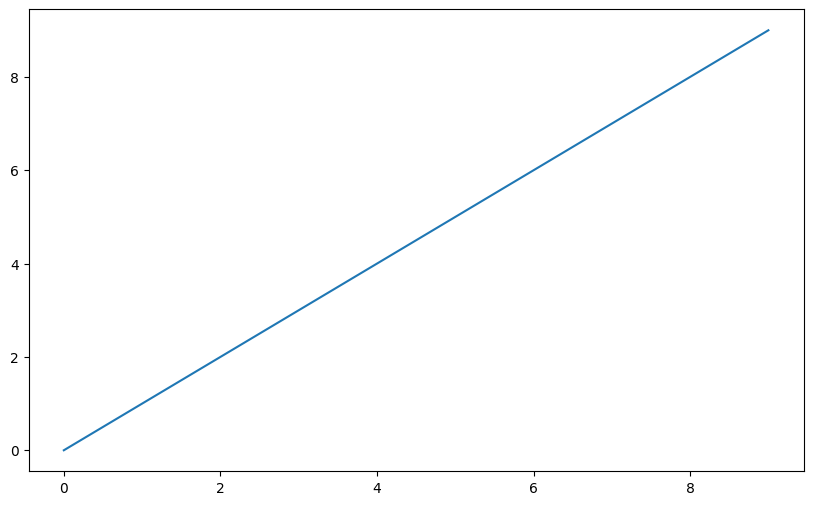

In [ ]:
#Calling the 'plot' function to plot y versus x as lines.
import numpy as np

#Create an array and pass it as a parameter to pyplot.plot

data = np.arange(10)
data
plt.plot(data)

### Figures and Subplots

From Matplotlib documentation: "When looking at Matplotlib visualization, you are almost always looking at Artists placed on a Figure. In the example below, the figure is the blue region and add_subplot has added an Axes artist to the Figure (see Parts of a Figure). A more complicated visualization can add multiple Axes to the Figure, colorbars, legends, annotations, and the Axes themselves can have multiple Artists added to them."

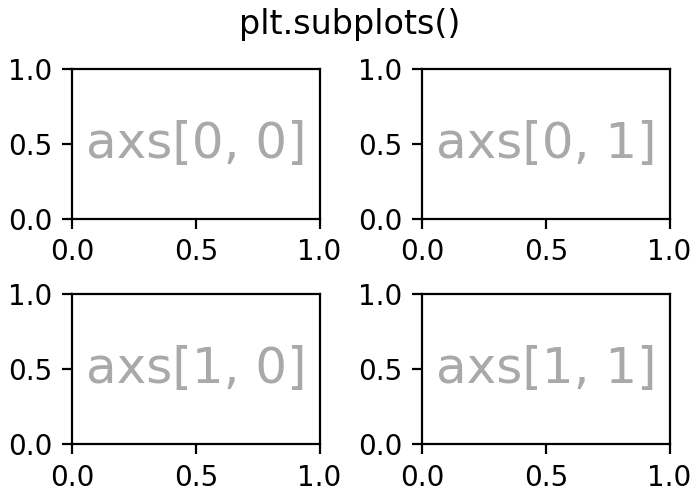

See: https://matplotlib.org/stable/users/explain/figure/index.html

In [ ]:
#Plots reside within a Figure.  Nothing shows until we add details.
#The following creates a figure object.
fig = plt.figure()

<Figure size 1000x600 with 0 Axes>

In [ ]:
#You can not make a plot with a blank figure. You have to create one or more subplots.
ax1 = fig.add_subplot(2, 2, 1)  #This figure is 2X2 and can support up to four figure and we are selecting the first one of four subplots.

In [ ]:
ax2 = fig.add_subplot(2, 2, 2) #Adding the next two subplots on thier repsective axis.
ax3 = fig.add_subplot(2, 2, 3)

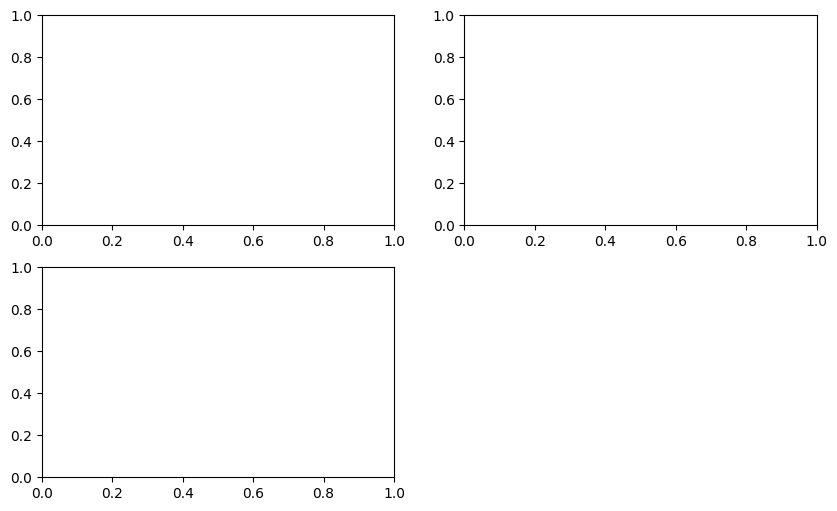

In [ ]:
#It is preferred to execute the creation of figures and sublots in a single cell:
#Using Jupyter notebooks, plots are reset after each cell is evaluated.  Complex plots require using a single cell.
fig = plt.figure()
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3)


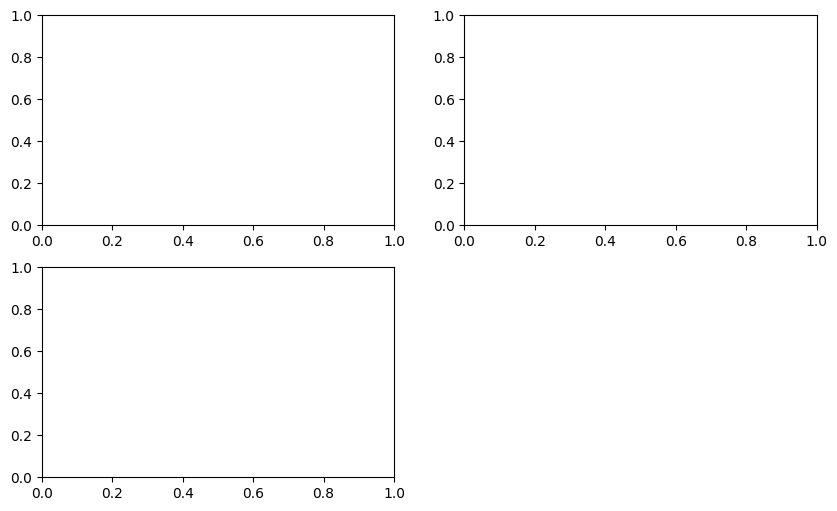

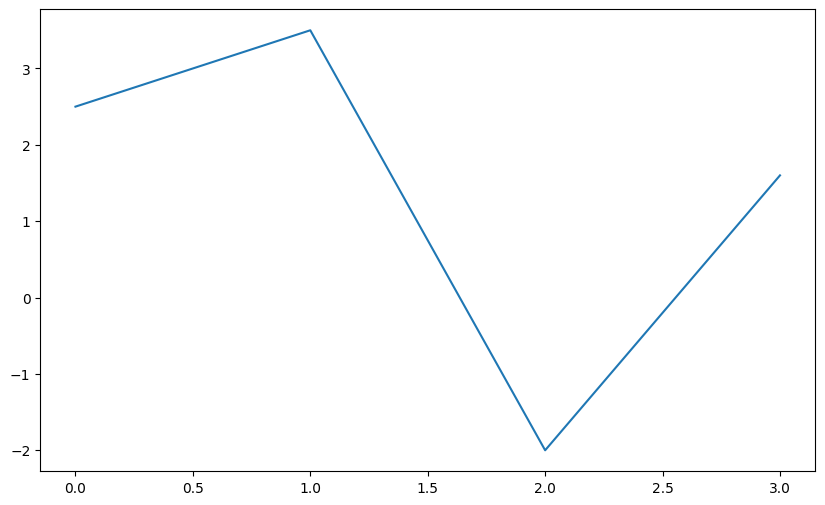

In [ ]:
#When we issue a plot command Matplotlib draws the on the last figure used and subplot used.
plt.plot([2.5,3.5,-2,1.6])
fig

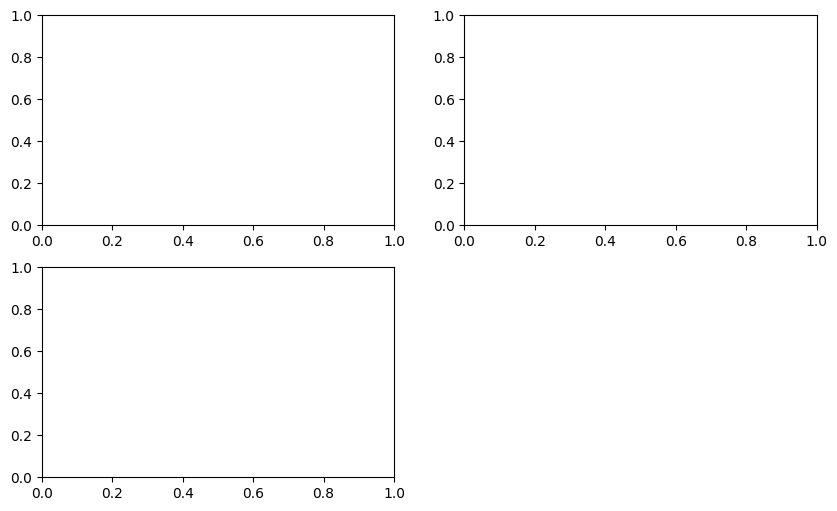

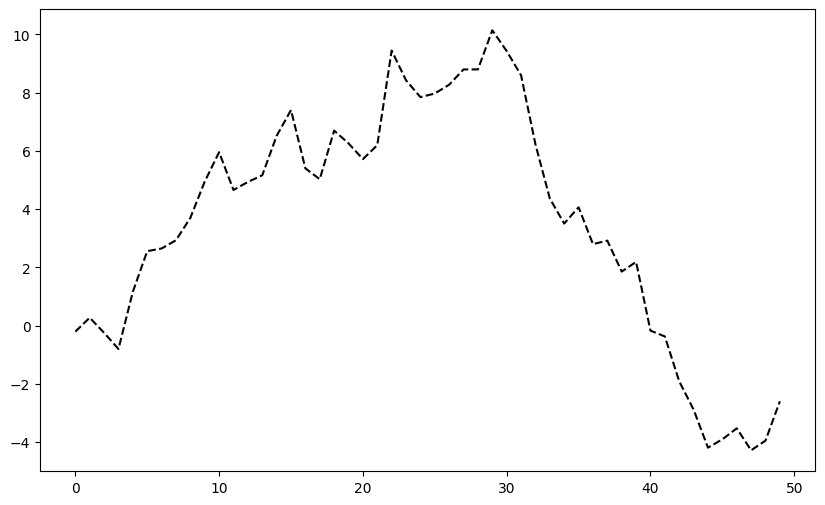

In [ ]:
#So, issuing the folowing command we get:

plt.plot(np.random.randn(50).cumsum(), 'k--') #'k--' formats the line to a black dashed line.
fig

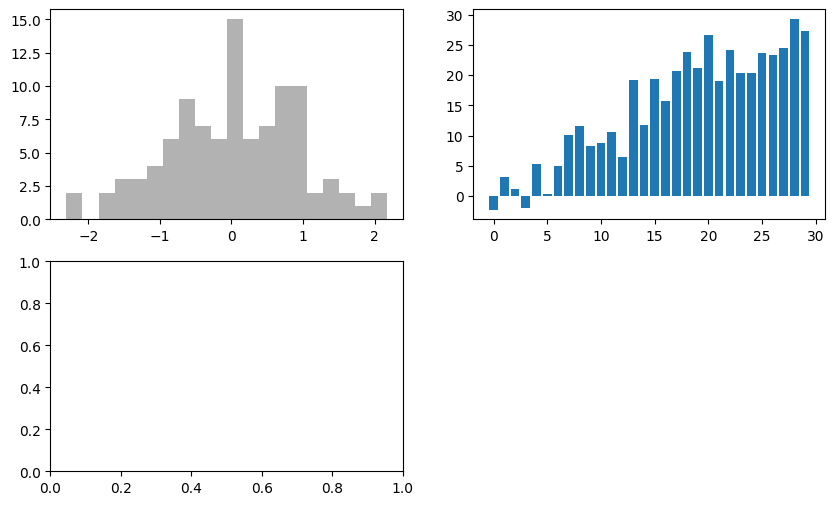

In [ ]:
#Objects returned by fig.add_subplot are AxisSubplot objects and can be plotted seperately
ax1.hist(np.random.randn(100), bins=20, color='k', alpha=0.3) #Plot a histogram on the first subplot
ax2.bar(np.arange(30), np.arange(30) + 3 * np.random.randn(30)) #PLot a bar graph in the second subplot.
fig

In [ ]:
#It is good practice to close the figure when plotting is complete.  Start with a clean canvas so to speak.
plt.close('all')

array([[<Axes: >, <Axes: >, <Axes: >],
       [<Axes: >, <Axes: >, <Axes: >]], dtype=object)

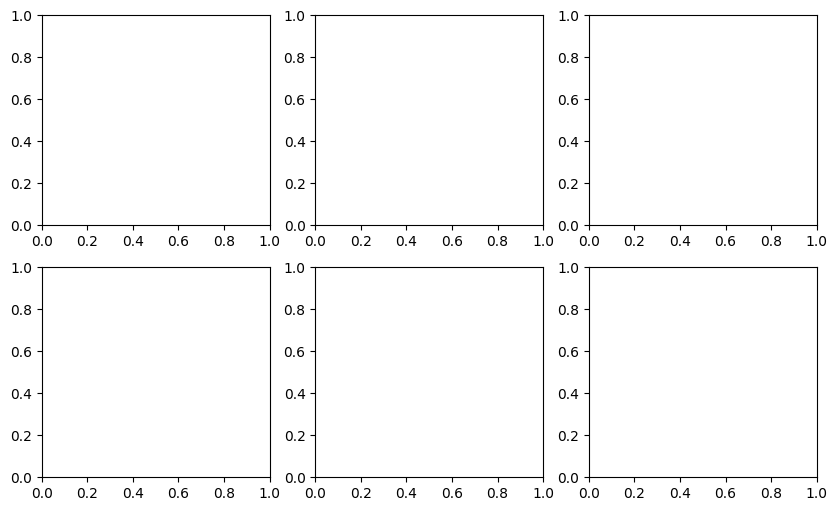

In [ ]:
#You can create multiple subplots using the "subplots" function.

fig, axes = plt.subplots(2, 3) # Creates a 2X3 figure with the  subplots.
axes

#### Adjusting the spacing around subplots

subplots_adjust(left=None, bottom=None, right=None, top=None,
                wspace=None, hspace=None)

fig, axes = plt.subplots(2, 2, sharex=True, sharey=True)
for i in range(2):
    for j in range(2):
        axes[i, j].hist(np.random.randn(500), bins=50, color='k', alpha=0.5)
plt.subplots_adjust(wspace=0, hspace=0)

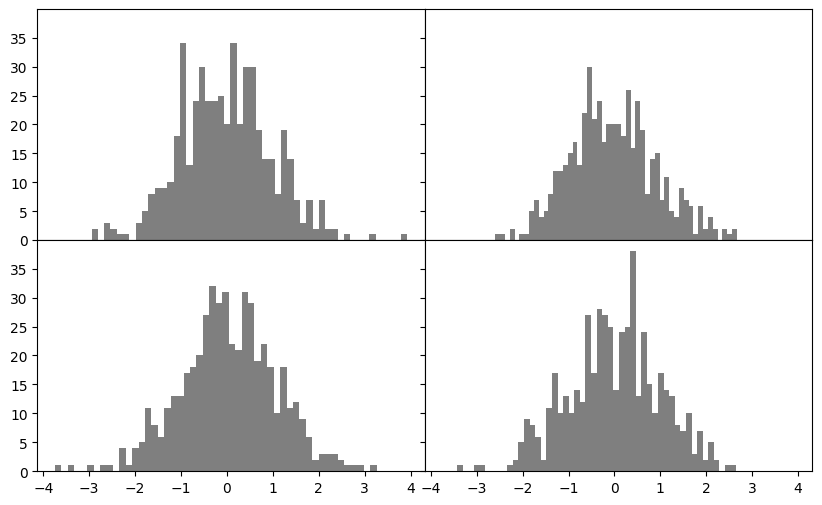

In [ ]:
#Spacing is relative to the hight and width between subplots.
#Change spacing using the sub_plots_adjust method.  The "sharex", and "sharey" parameters
#controls sharing x or y axes.

#See documentation in a tab for details.
#Parameters
#nrows, ncols : int, default: 1
#    Number of rows/columns of the subplot grid.

#sharex, sharey : bool or {'none', 'all', 'row', 'col'}, default: False
#    Controls sharing of properties among x (*sharex*) or y (*sharey*) axes:
#
#True or 'all': x- or y-axis will be shared among all subplots.
#False or 'none': each subplot x- or y-axis will be independent.
#'row': each subplot row will share an x- or y-axis.
#'col': each subplot column will share an x- or y-axis.
#    When subplots have a shared x-axis along a column, only the x tick labels of the bottom subplot are created. Similarly, when subplots have a shared y-axis along a row, only the y tick labels of the first column subplot are created. To later turn other subplots' ticklabels on, use ~matplotlib.axes.Axes.tick_params.

fig, axes = plt.subplots(2, 2, sharex=True, sharey=True)
for i in range(2):
    for j in range(2):
        axes[i, j].hist(np.random.randn(500), bins=50, color='k', alpha=0.5)
plt.subplots_adjust(wspace=0, hspace=0)

### Colors, Markers, and Line Styles

Matplotlib's main plot function accepts arrays of x and y coordinates and optionally abbreviations for color and line style

ax.plot(x, y, 'g--')

The same plot can also be generated by:

ax.plot(x, y, linestyle='--', color='g')

In [ ]:
plt.figure()

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

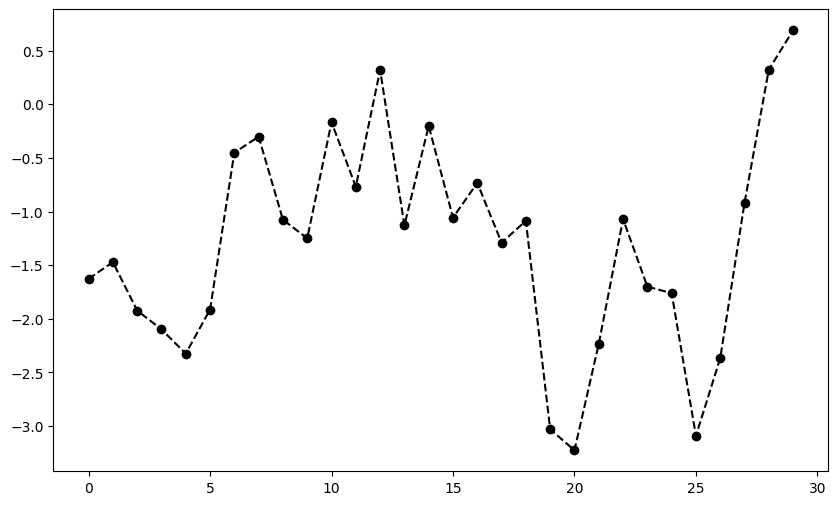

In [ ]:
#Markers highlighting data points are inferred and continous.  Markers can be part of the line style.
from numpy.random import randn
plt.plot(randn(30).cumsum(), 'ko--')

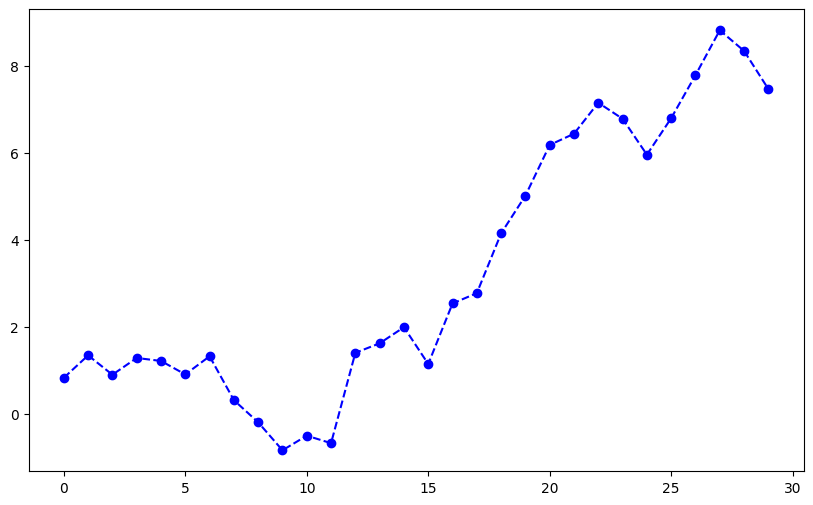

In [ ]:
#Alternatively, specifically specified.
plt.plot(randn(30).cumsum(), color='b', linestyle='dashed', marker='o')

In [ ]:
plt.close('all')

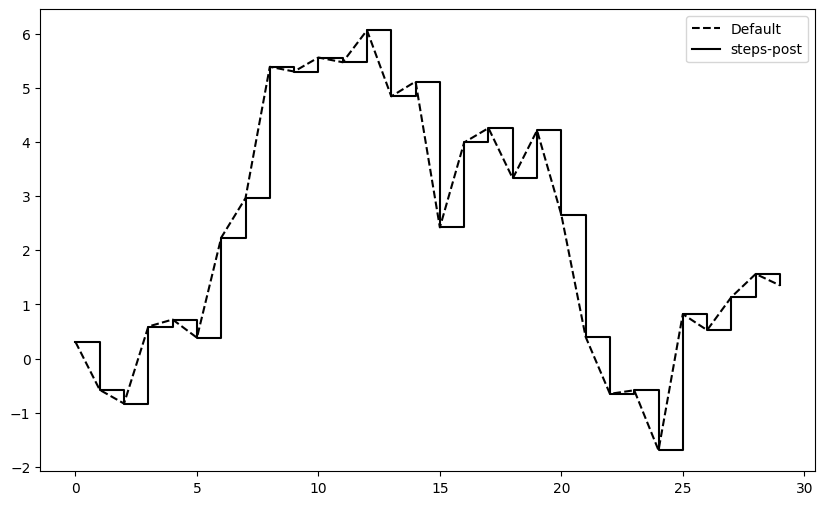

In [ ]:
#Line plots are linearly interpolated by default.  You can cange the default type
data = np.random.randn(30).cumsum()
plt.plot(data, 'k--', label='Default')
plt.plot(data, 'k-', drawstyle='steps-post', label='steps-post')

#Locates a legend in the "best" location on the plot. See Documentation for details
plt.legend(loc='best')

### Ticks, Labels, and Legends

#### Setting the title, axis labels, ticks, and ticklabels

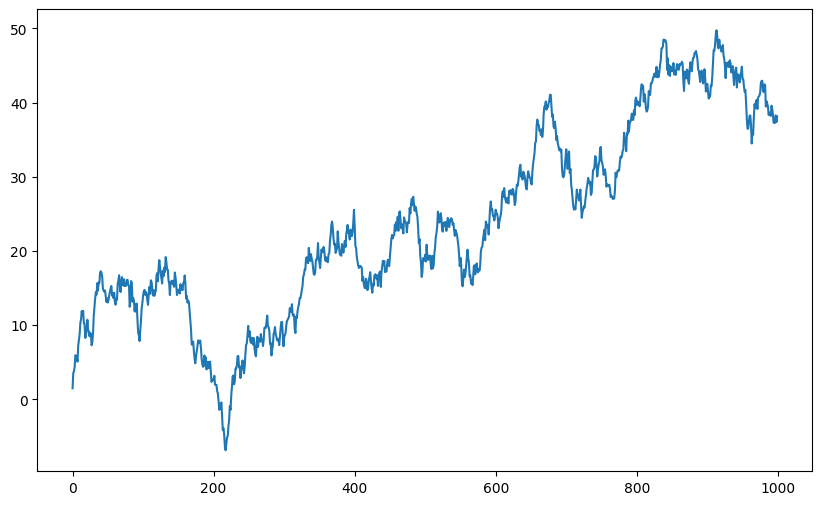

In [ ]:
#PLot a set of random numbers.
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.plot(np.random.randn(1000).cumsum())

In [ ]:
#Ticks, Labels, and Legends use pyplot interface and act on the most recent AxesSubplot.
ticks = ax.set_xticks([0, 250, 500, 750, 1000])
labels = ax.set_xticklabels(['one', 'two', 'three', 'four', 'five'],
                            rotation=30, fontsize='small')

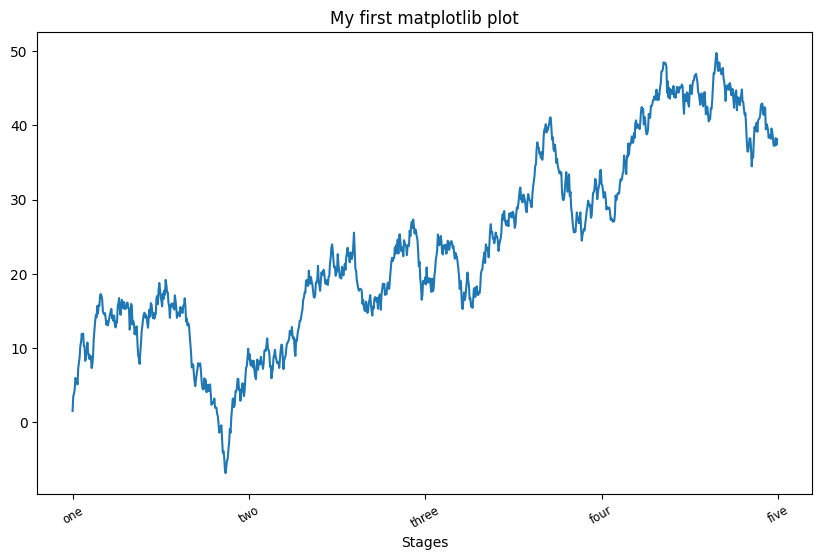

In [ ]:
#set the title and x axes label
ax.set_title('My first matplotlib plot')
ax.set_xlabel('Stages')
fig

props = {
    'title': 'My first matplotlib plot',
    'xlabel': 'Stages'
}
ax.set(**props)

#### Adding legends

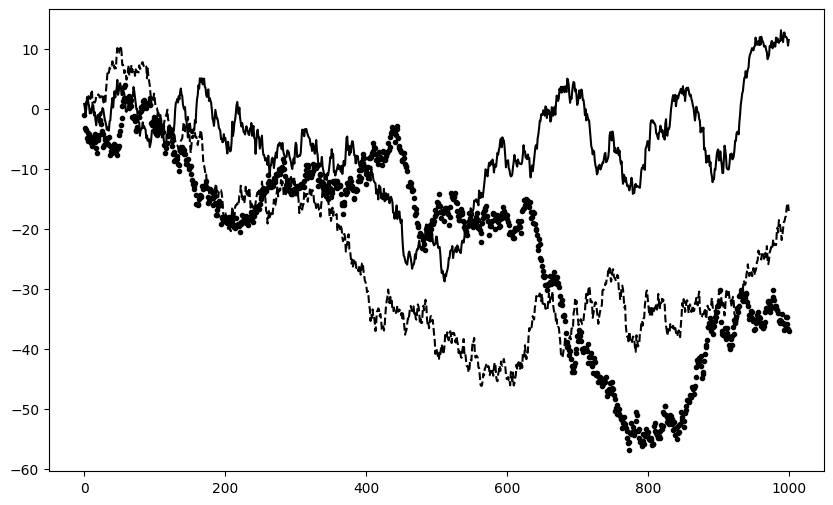

In [ ]:
from numpy.random import randn
fig = plt.figure(); ax = fig.add_subplot(1, 1, 1)
ax.plot(randn(1000).cumsum(), 'k', label='one')
ax.plot(randn(1000).cumsum(), 'k--', label='two')
ax.plot(randn(1000).cumsum(), 'k.', label='three')

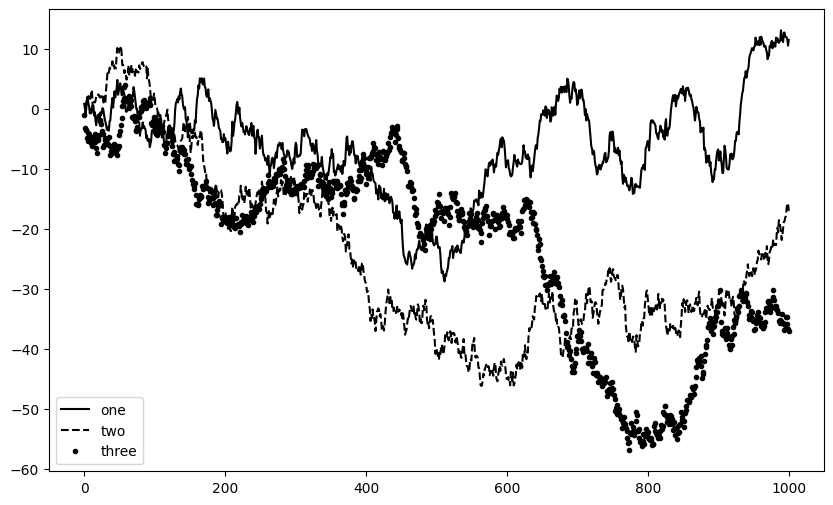

In [ ]:
#loc option places Matplotlib where to put the plot
#The legend method has several options.
ax.legend(loc='best')
fig

### Annotations and Drawing on a Subplot

#Annotations allows you to draw on your plot.
#You can add annotations using the test, arrow, and anotate functions.
ax.text(x, y, 'Hello world!',
        family='monospace', fontsize=10)

Text(0.5, 1.0, 'Important dates in the 2008-2009 financial crisis')

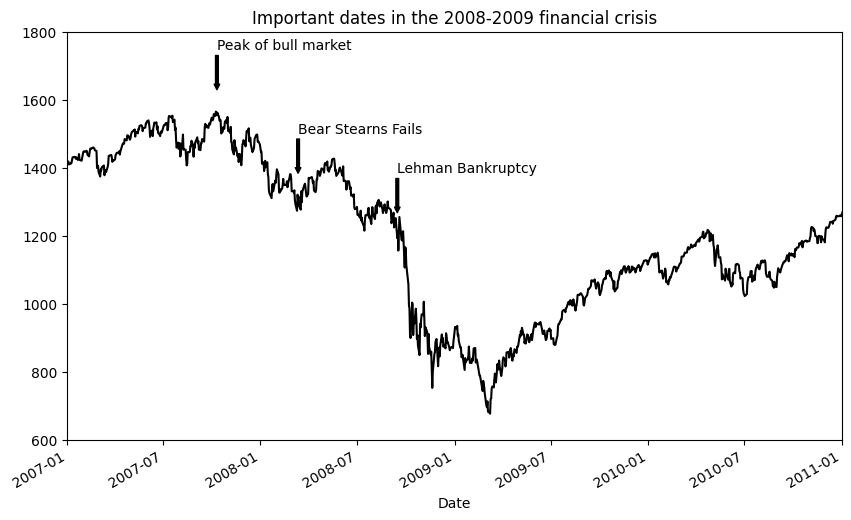

In [ ]:
from datetime import datetime

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

#Remember the file needs to be in the working directory
data = pd.read_csv('/content/MSSP6070/data/spx.csv', index_col=0, parse_dates=True)
spx = data['SPX']

#Plot on the subplot created above.
spx.plot(ax=ax, style='k-')

crisis_data = [
    (datetime(2007, 10, 11), 'Peak of bull market'),
    (datetime(2008, 3, 12), 'Bear Stearns Fails'),
    (datetime(2008, 9, 15), 'Lehman Bankruptcy')
]

for date, label in crisis_data:
    ax.annotate(label, xy=(date, spx.asof(date) + 75), #draws lables at the indicated x,y coordinates
                xytext=(date, spx.asof(date) + 225),
                arrowprops=dict(facecolor='black', headwidth=4, width=2,
                                headlength=4),
                horizontalalignment='left', verticalalignment='top')

# Zoom in on 2007-2010
ax.set_xlim(['1/1/2007', '1/1/2011']) #sets the boundaries of the plot rather tha using the default values formMatplotlib
ax.set_ylim([600, 1800])

ax.set_title('Important dates in the 2008-2009 financial crisis') #Adds a tile to the Plot

In [ ]:
ax.set_title('Important dates in the 2008–2009 financial crisis')

Text(0.5, 1.0, 'Important dates in the 2008–2009 financial crisis')

In [ ]:
#Saves the plot to a file.  Supported formats include PDF, PNG, and most other formats.
#See documentation for details
fig.savefig('/content/MSSP6070/WeeklyModules/Week07/Stock1.pdf')

Drawing shapes is also possible, but requires some thought: Shapes are referred to as patches

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

rect = plt.Rectangle((0.2, 0.75), 0.4, 0.15, color='k', alpha=0.3)
circ = plt.Circle((0.7, 0.2), 0.15, color='b', alpha=0.3)
pgon = plt.Polygon([[0.15, 0.15], [0.35, 0.4], [0.2, 0.6]],
                   color='g', alpha=0.5)

ax.add_patch(rect)
ax.add_patch(circ)
ax.add_patch(pgon)

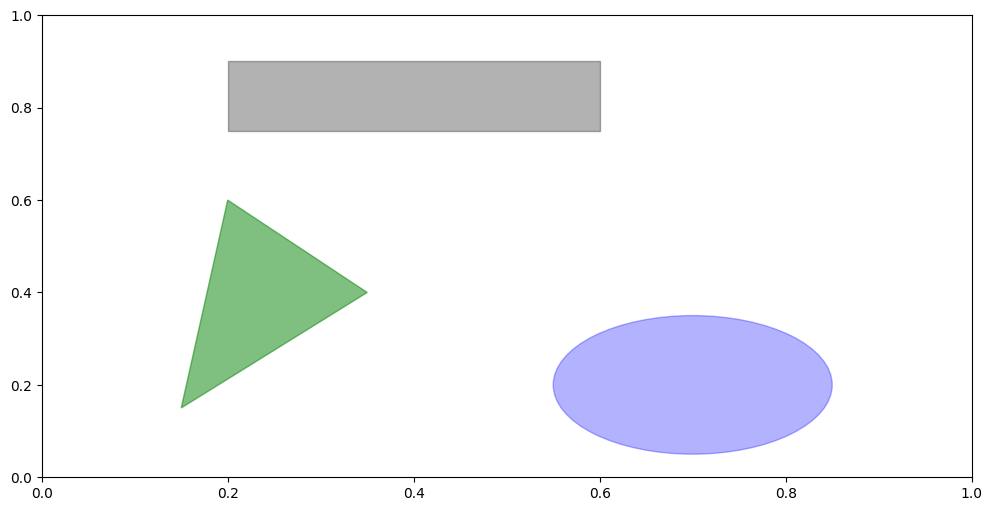

In [ ]:
fig = plt.figure(figsize=(12, 6)); ax = fig.add_subplot(1, 1, 1)
rect = plt.Rectangle((0.2, 0.75), 0.4, 0.15, color='k', alpha=0.3)
circ = plt.Circle((0.7, 0.2), 0.15, color='b', alpha=0.3)
pgon = plt.Polygon([[0.15, 0.15], [0.35, 0.4], [0.2, 0.6]],
                   color='g', alpha=0.5)
ax.add_patch(rect)
ax.add_patch(circ)
ax.add_patch(pgon)

### Saving Plots to File

plt.savefig('figpath.svg')

In [ ]:
#Saves the plot to the defualt location
fig.savefig('Stock.pdf')

plt.savefig('figpath.png', dpi=400, bbox_inches='tight')

How to save a Matplotlib figure to an in-memory buffer rather than directly to a file on disk.

from io import BytesIO
buffer = BytesIO()
plt.savefig(buffer)
plot_data = buffer.getvalue()

### matplotlib Configuration

plt.rc('figure', figsize=(10, 10))

font_options = {'family' : 'monospace',
                'weight' : 'bold',
                'size'   : 'small'}
plt.rc('font', **font_options)

In [ ]:
#the "rc" function sets runtime configuration options.
plt.rc('figure', figsize=(10, 10))

In [ ]:
plt.close("all")

## Plotting with pandas and seaborn
You can use Pandas or Seaborn to create visualizations.  Matplotlib is generally more robust with greater options, but that is my oppinion.

Listed below are some basic differences in syntax.

### Line Plots

In [ ]:
#Just in case....close previously created figures.
plt.close('all')

<Axes: >

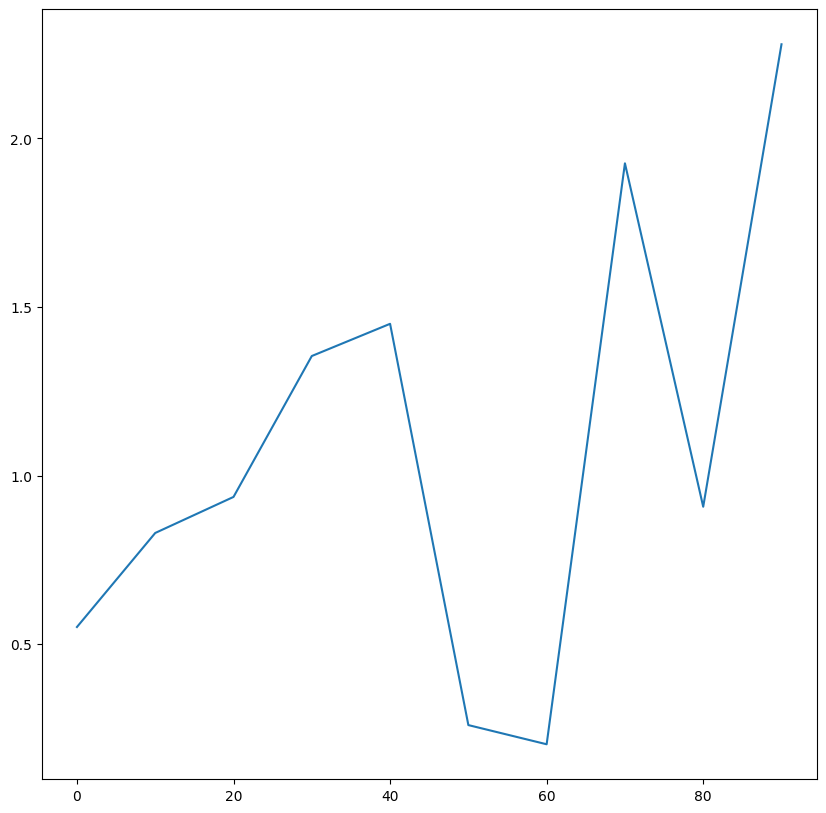

In [ ]:
s = pd.Series(np.random.randn(10).cumsum(), index=np.arange(0, 100, 10))
s.plot()

<Axes: >

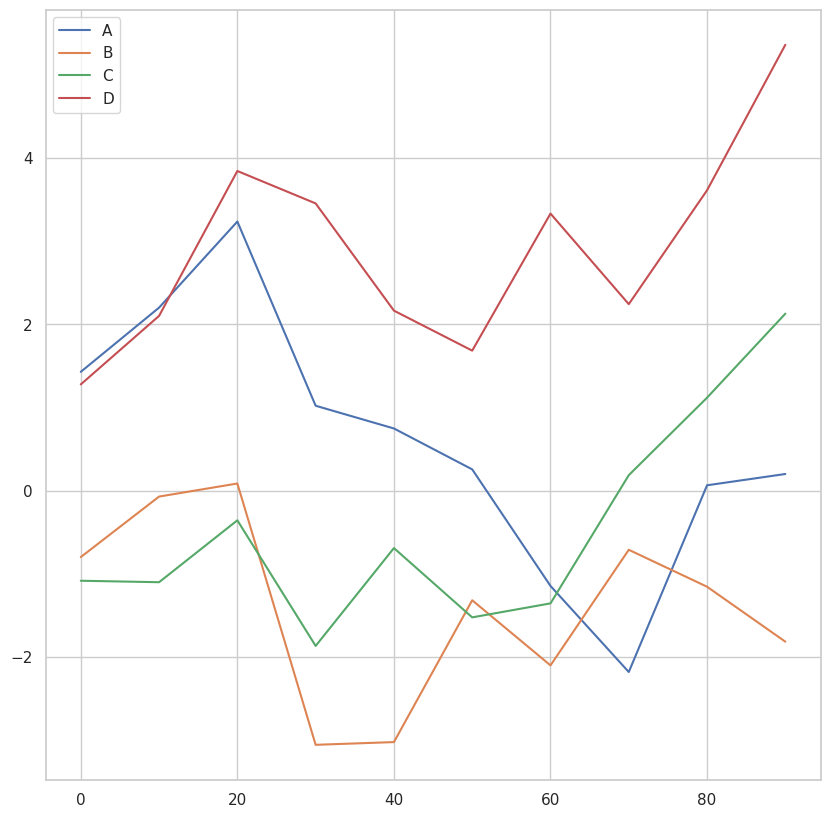

In [ ]:
df = pd.DataFrame(np.random.randn(10, 4).cumsum(0),
                  columns=['A', 'B', 'C', 'D'],
                  index=np.arange(0, 100, 10))
df
df.plot()

### Bar Plots

<Axes: >

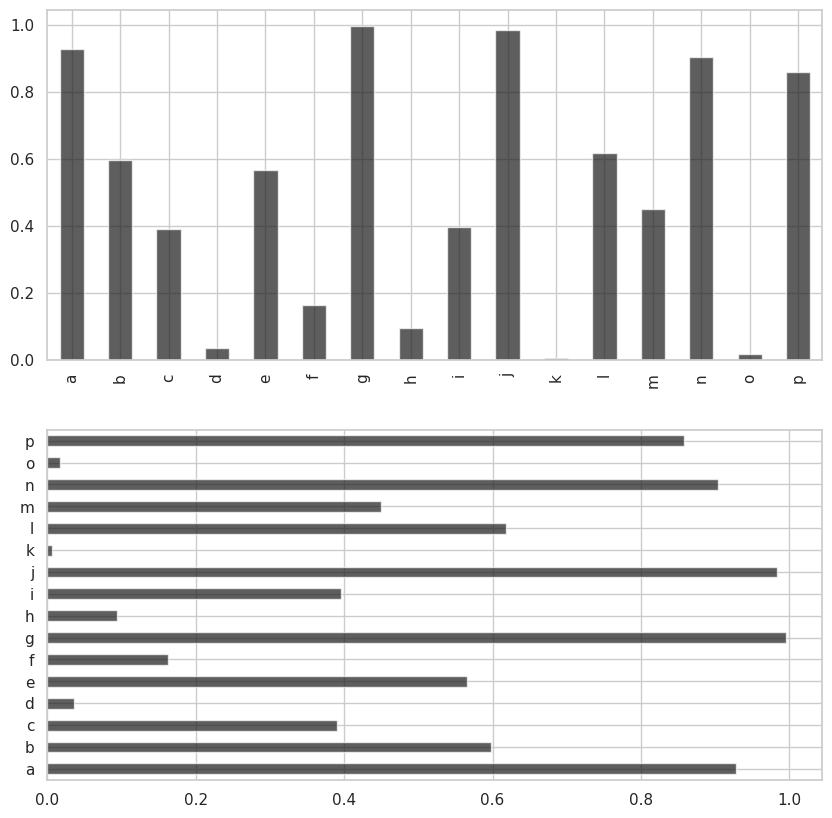

In [ ]:
fig, axes = plt.subplots(2, 1)
data = pd.Series(np.random.rand(16), index=list('abcdefghijklmnop'))
data.plot.bar(ax=axes[0], color='k', alpha=0.7)
data.plot.barh(ax=axes[1], color='k', alpha=0.7)

In [ ]:
np.random.seed(12348)

<Axes: >

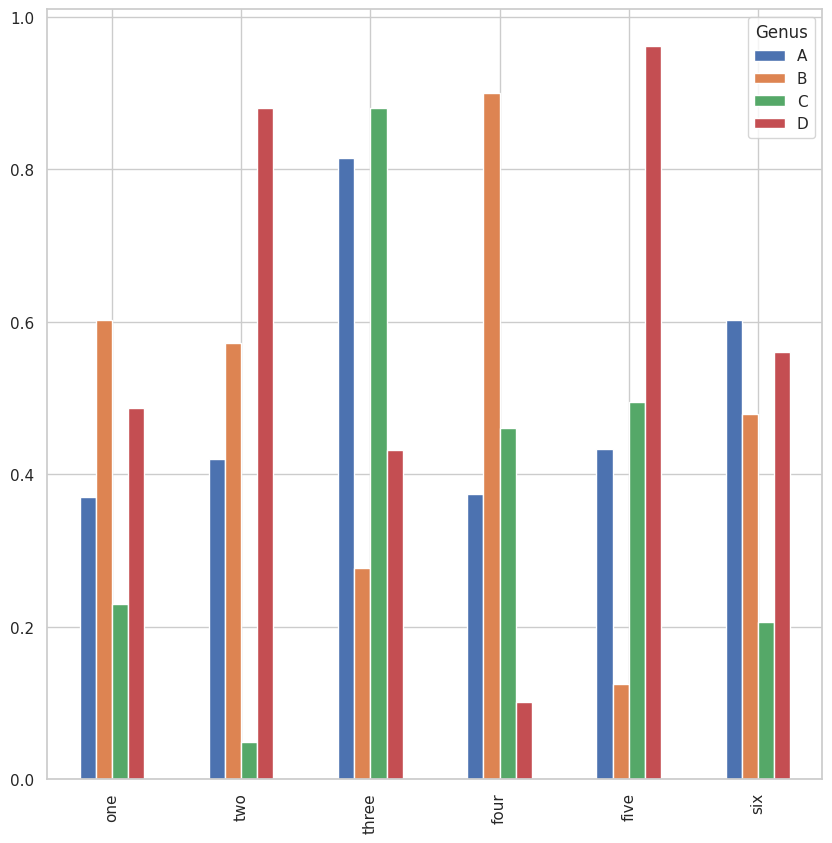

In [ ]:
df = pd.DataFrame(np.random.rand(6, 4),
                  index=['one', 'two', 'three', 'four', 'five', 'six'],
                  columns=pd.Index(['A', 'B', 'C', 'D'], name='Genus'))
df
df.plot.bar()

In [ ]:
plt.figure()

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

<Axes: >

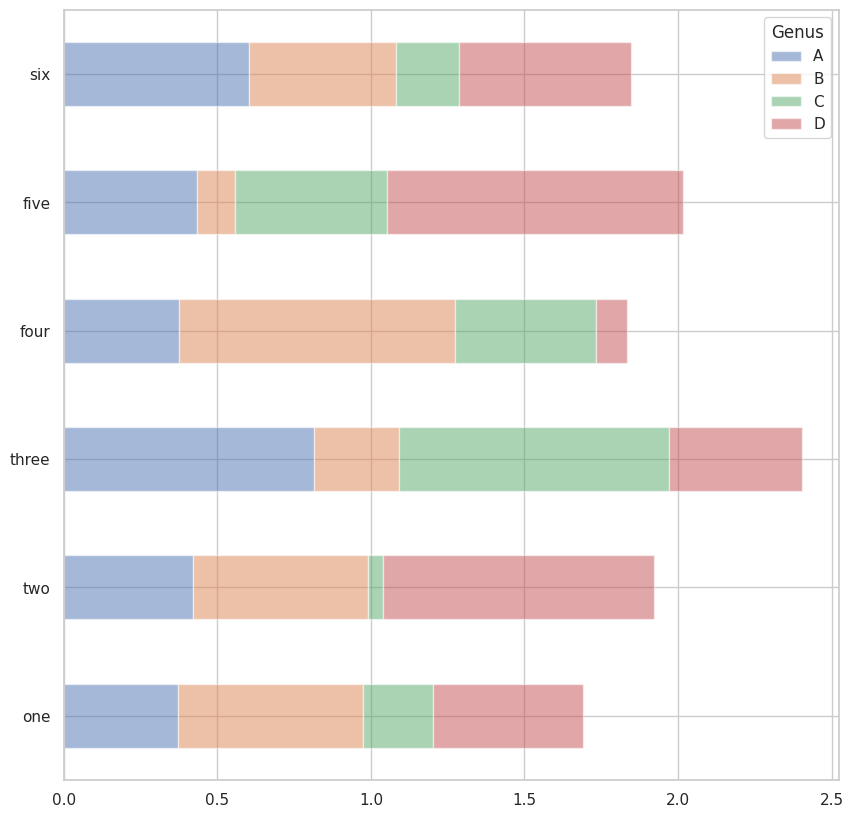

In [ ]:
df.plot.barh(stacked=True, alpha=0.5)

In [ ]:
plt.close('all')

In [ ]:
# Ensure the csv file is downloaded from the course and located in the correct directory.
tips = pd.read_csv('/content/drive/MyDrive/MSSP607/Modules/Week07/Examples/tips.csv')
party_counts = pd.crosstab(tips['day'], tips['size'])
party_counts
# Not many 1- and 6-person parties
party_counts = party_counts.loc[:, 2:5]
tips

,total_bill,tip,smoker,day,time,size
0,16.99,1.01,No,Sun,Dinner,2
1,10.34,1.66,No,Sun,Dinner,3
2,21.01,3.50,No,Sun,Dinner,3
3,23.68,3.31,No,Sun,Dinner,2
4,24.59,3.61,No,Sun,Dinner,4
...,...,...,...,...,...,...
239,29.03,5.92,No,Sat,Dinner,3
240,27.18,2.00,Yes,Sat,Dinner,2
241,22.67,2.00,Yes,Sat,Dinner,2
242,17.82,1.75,No,Sat,Dinner,2


<Axes: xlabel='day'>

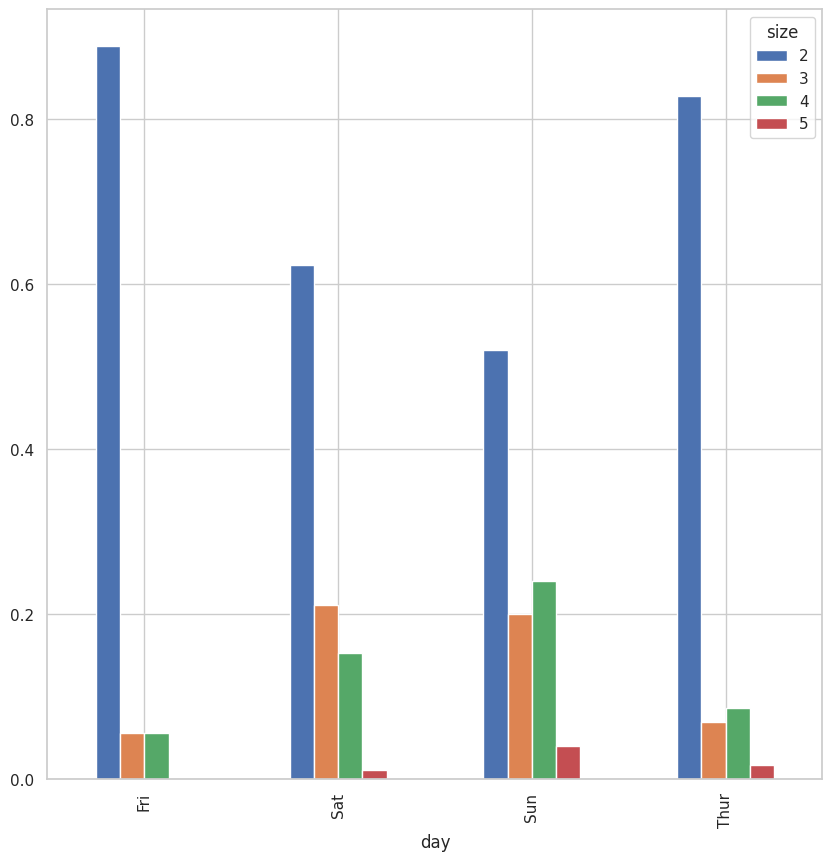

In [ ]:
# Normalize to sum to 1
party_pcts = party_counts.div(party_counts.sum(1), axis=0)
party_pcts
party_pcts.plot.bar()

In [ ]:
plt.close('all')

<Axes: xlabel='tip_pct', ylabel='day'>

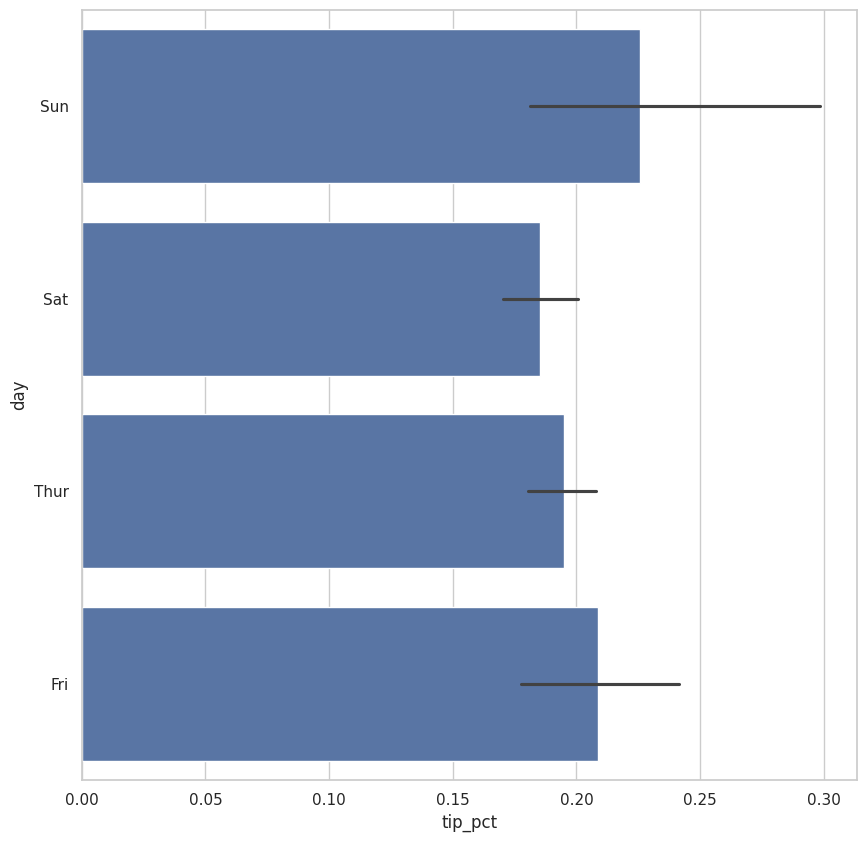

In [ ]:
import seaborn as sns
tips['tip_pct'] = tips['tip'] / (tips['total_bill'] - tips['tip'])
tips.head()
sns.barplot(x='tip_pct', y='day', data=tips, orient='h')

In [ ]:
plt.close('all')

<Axes: xlabel='tip_pct', ylabel='day'>

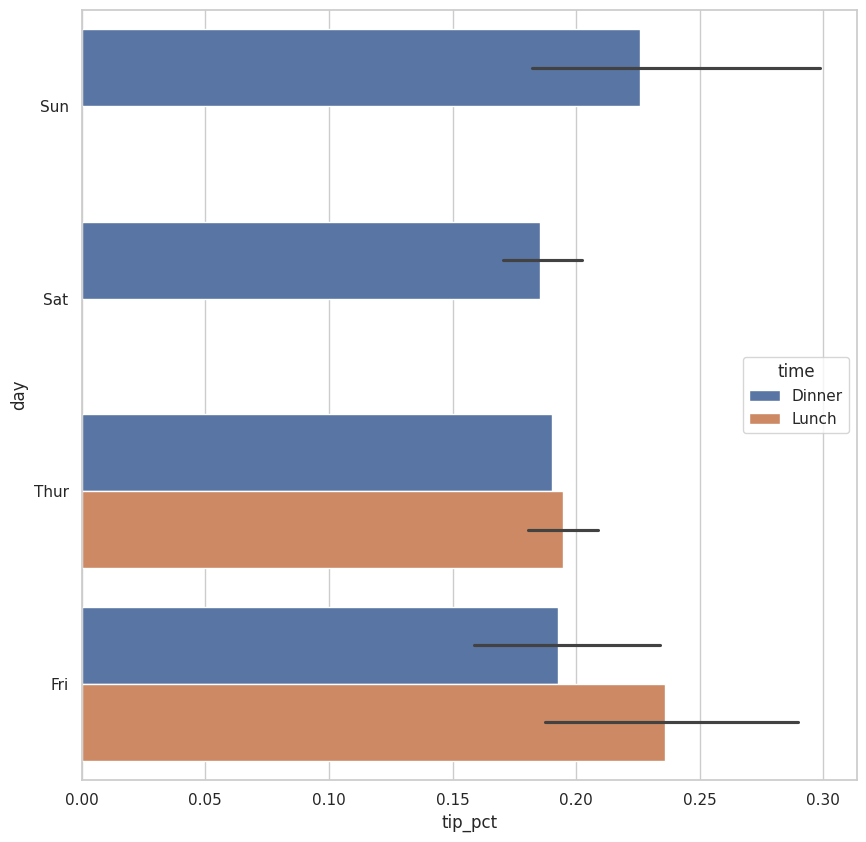

In [ ]:
sns.barplot(x='tip_pct', y='day', hue='time', data=tips, orient='h')

In [ ]:
plt.close('all')

In [ ]:
sns.set(style="whitegrid")

### Histograms and Density Plots

In [ ]:
plt.figure()

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

<Axes: ylabel='Frequency'>

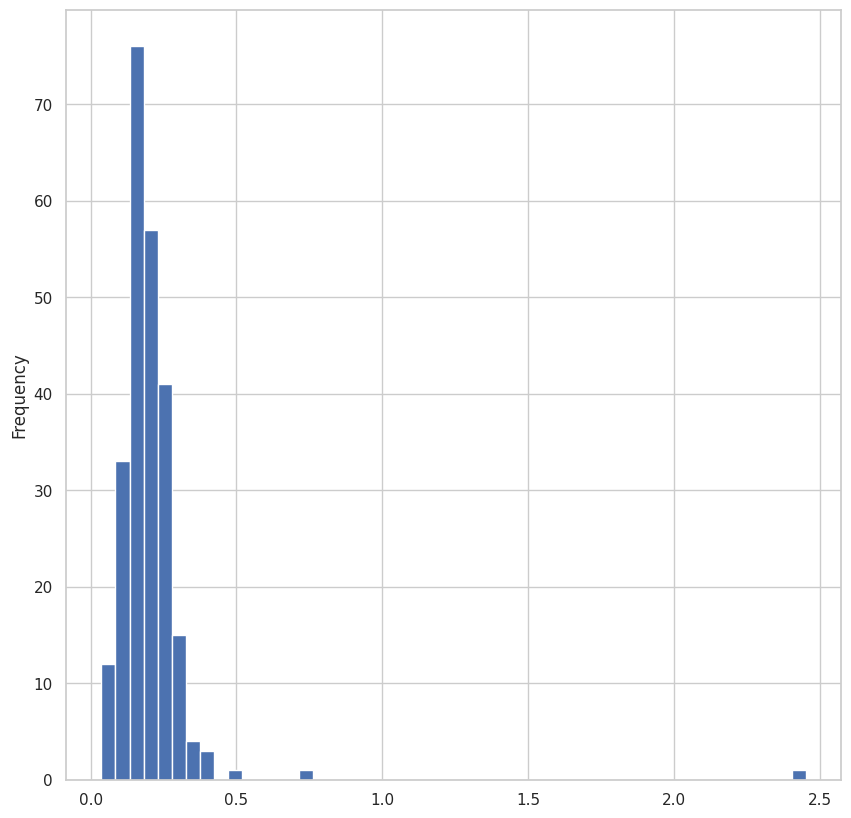

In [ ]:
tips['tip_pct'].plot.hist(bins=50)

In [ ]:
plt.figure()

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

<Axes: ylabel='Density'>

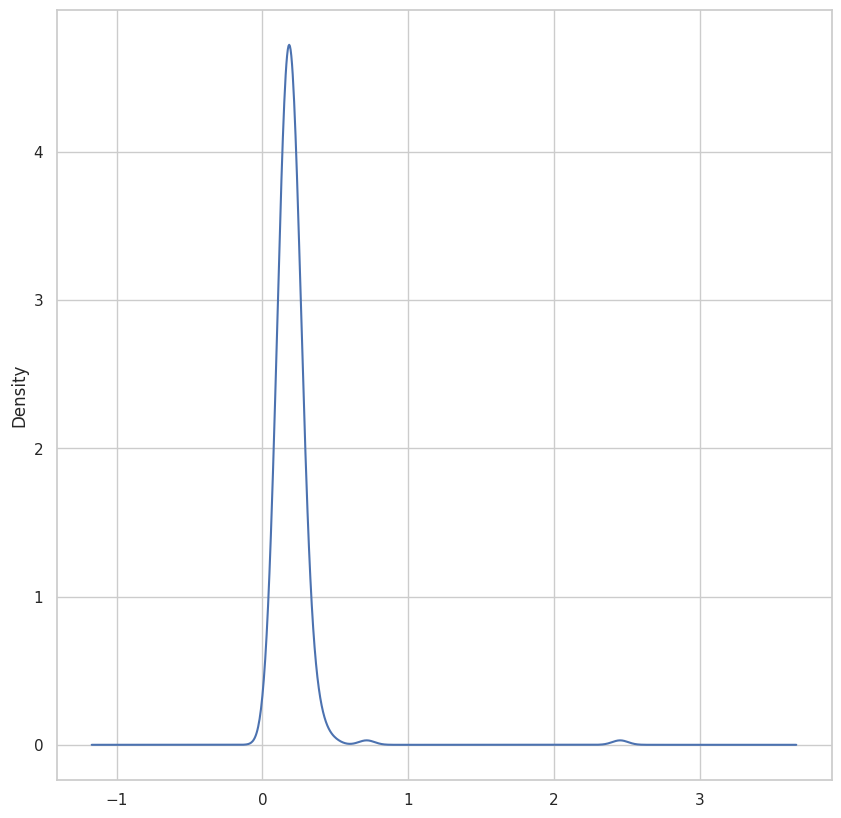

In [ ]:
tips['tip_pct'].plot.density()

In [ ]:
plt.figure()

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

<ipython-input-363-be41c4d427fd>:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(values, bins=100, color='k')


<Axes: ylabel='Density'>

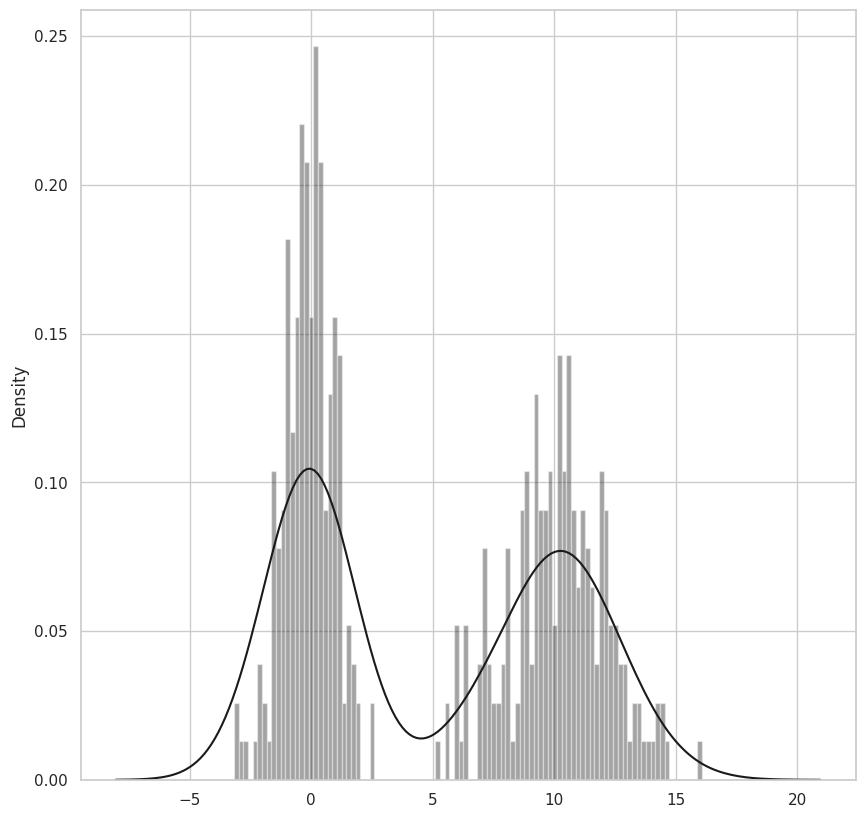

In [ ]:
comp1 = np.random.normal(0, 1, size=200)
comp2 = np.random.normal(10, 2, size=200)
values = pd.Series(np.concatenate([comp1, comp2]))
sns.distplot(values, bins=100, color='k')

### Scatter or Point Plots

In [ ]:
# Ensure the csv file is downloaded from the course and located in the correct directory.
#The file contains macro economi indicators.
macro = pd.read_csv('/content/drive/MyDrive/MSSP607/Modules/Week07/Examples/macrodata.csv')
data = macro[['cpi', 'm1', 'tbilrate', 'unemp']]
trans_data = np.log(data).diff().dropna()
trans_data[-5:]

,cpi,m1,tbilrate,unemp
198,-0.007904,0.045361,-0.396881,0.105361
199,-0.021979,0.066753,-2.277267,0.139762
200,0.002340,0.010286,0.606136,0.160343
201,0.008419,0.037461,-0.200671,0.127339
202,0.008894,0.012202,-0.405465,0.042560


In [ ]:
plt.figure()

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

In [ ]:
trans_data

,cpi,m1,tbilrate,unemp
1,0.005849,0.014215,0.088193,-0.128617
2,0.006838,-0.008505,0.215321,0.038466
3,0.000681,-0.003565,0.125317,0.055060
4,0.005772,-0.002861,-0.212805,-0.074108
5,0.000338,0.004289,-0.266946,0.000000
...,...,...,...,...
198,-0.007904,0.045361,-0.396881,0.105361
199,-0.021979,0.066753,-2.277267,0.139762
200,0.002340,0.010286,0.606136,0.160343
201,0.008419,0.037461,-0.200671,0.127339


Text(0.5, 1.0, 'Changes in log m1 versus log unemp')

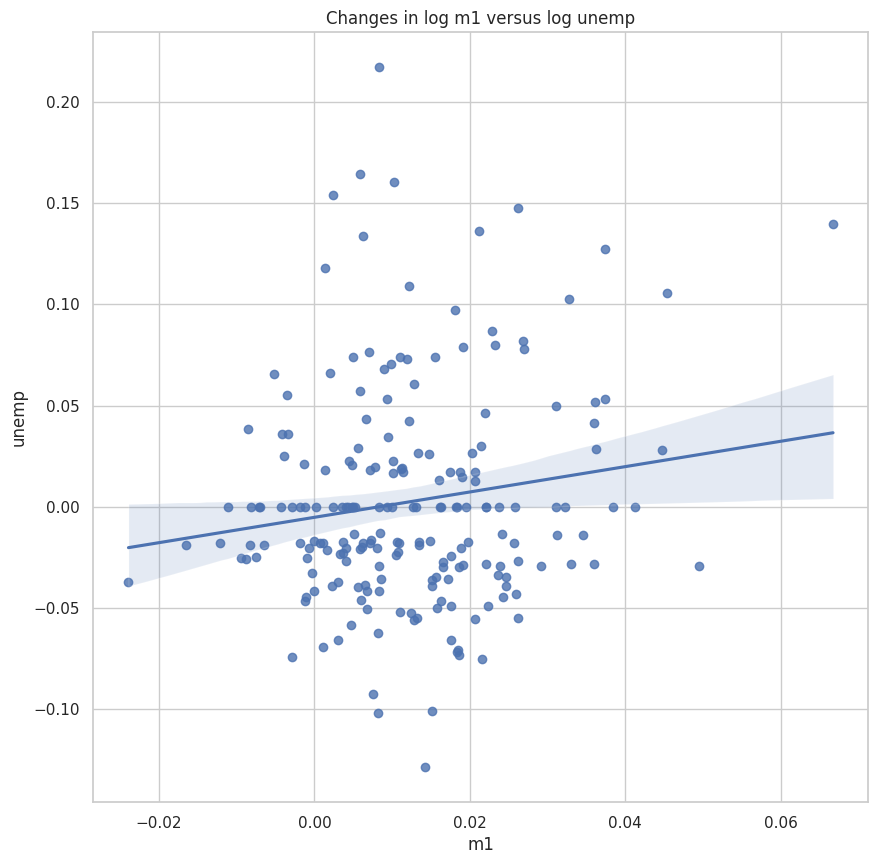

In [ ]:
#Specify x and y axis data and data source
sns.regplot(x='m1', y='unemp', data=trans_data)
plt.title('Changes in log %s versus log %s' % ('m1', 'unemp'))

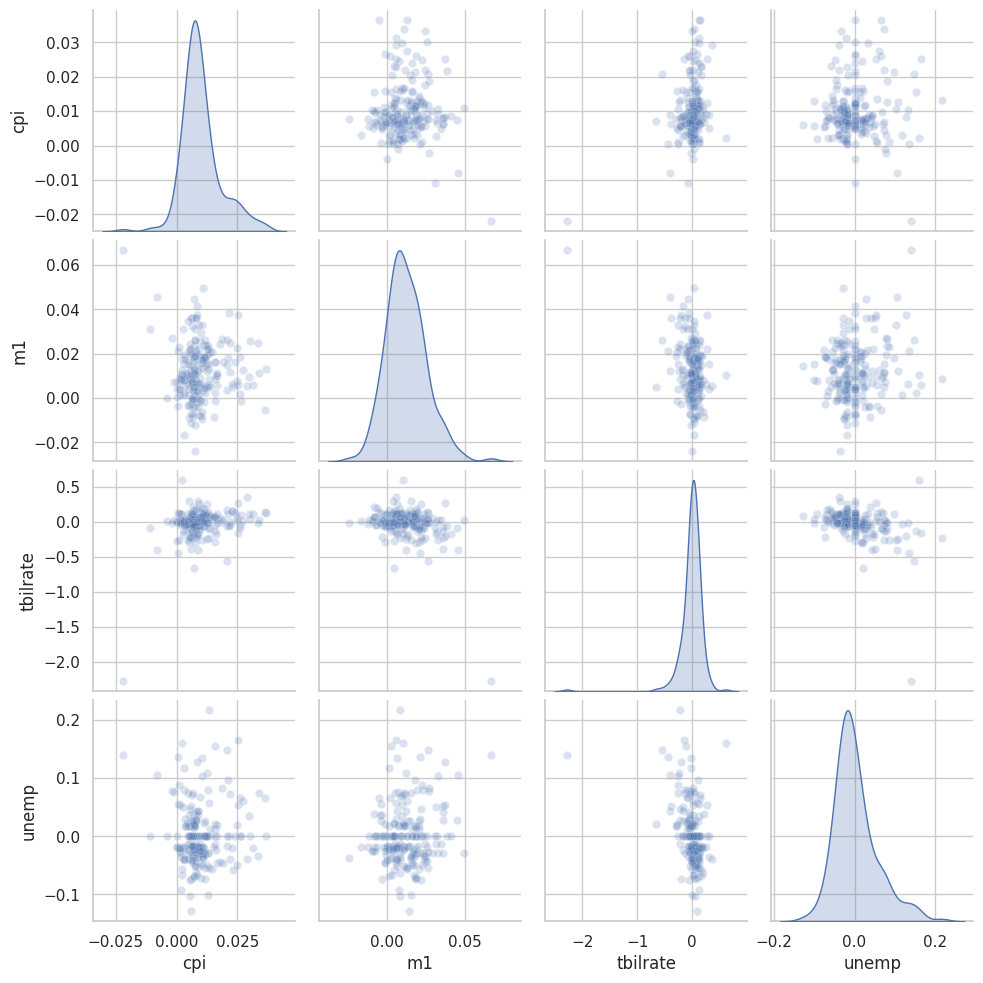

In [ ]:
#Plot pairwise relationships in a data set.
sns.pairplot(trans_data, diag_kind='kde', plot_kws={'alpha': 0.2})

### Facet Grids and Categorical Data

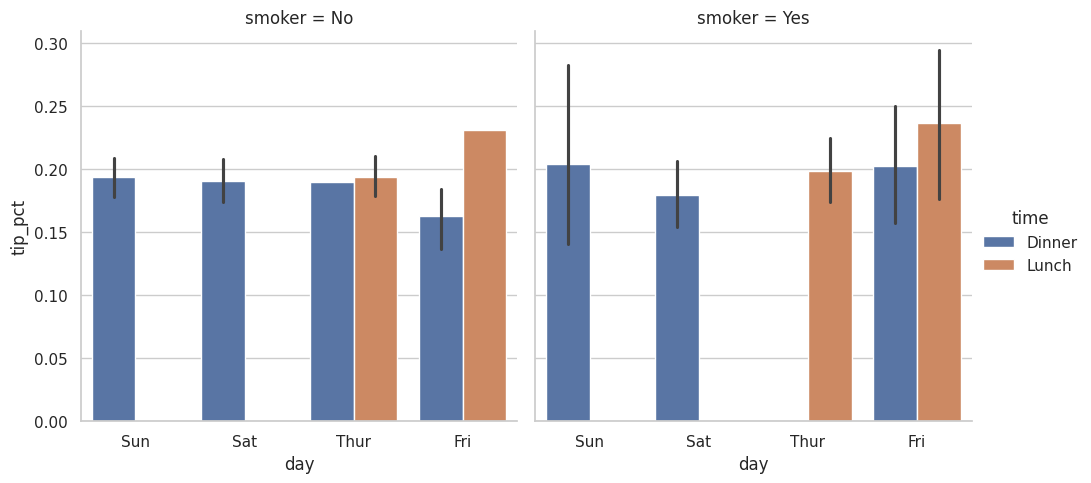

In [ ]:
sns.catplot(x='day', y='tip_pct', hue='time', col='smoker', kind='bar', data=tips[tips.tip_pct < 1])

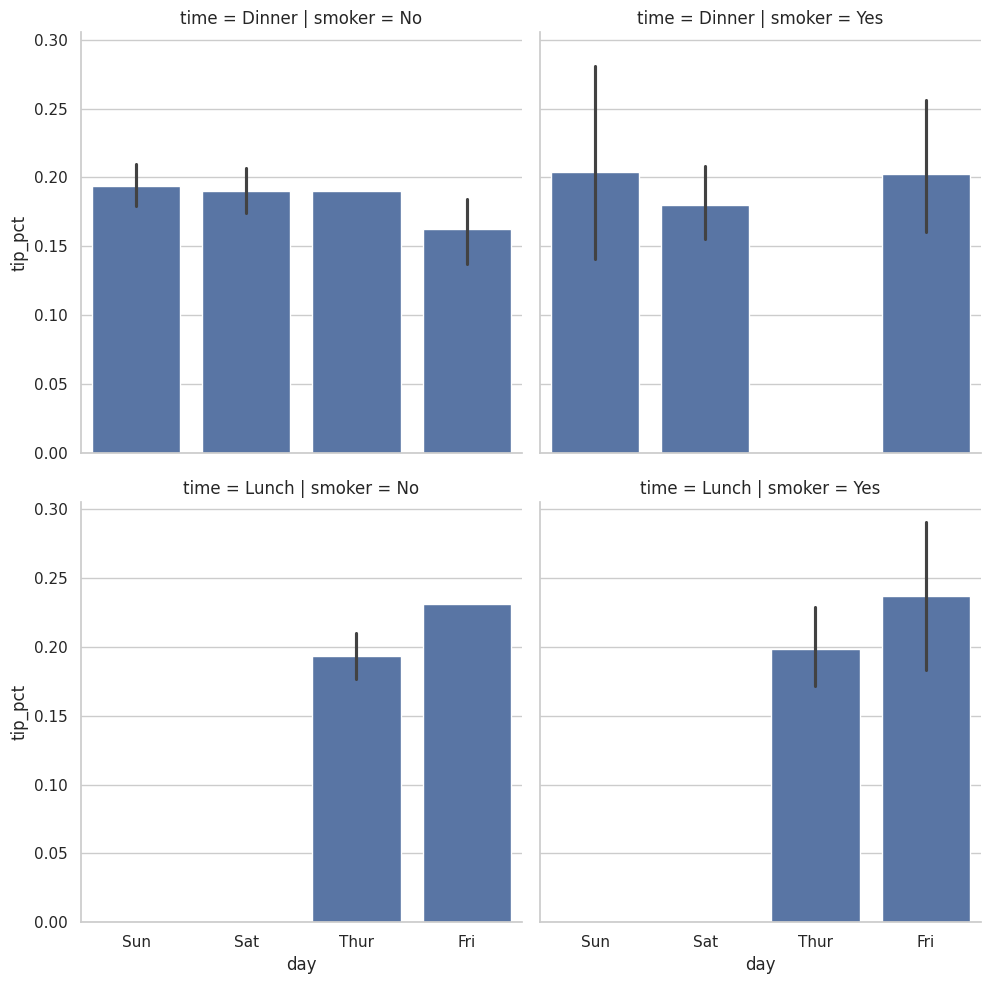

In [ ]:
sns.catplot(x='day', y='tip_pct', row='time',
               col='smoker',
               kind='bar', data=tips[tips.tip_pct < 1])

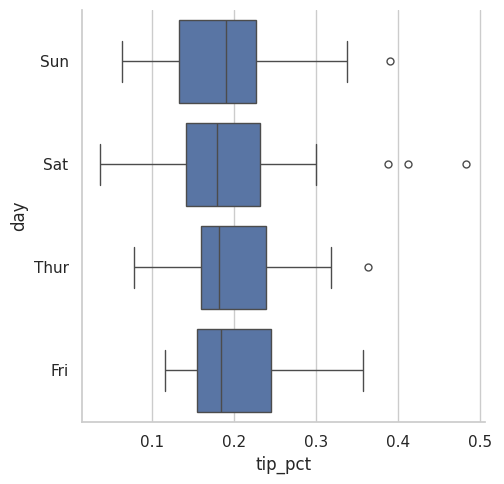

In [ ]:
sns.catplot(x='tip_pct', y='day', kind='box',
               data=tips[tips.tip_pct < 0.5])

## Other Python Visualization Tools

In [ ]:
pd.options.display.max_rows = PREVIOUS_MAX_ROWS

## Conclusion